In [1]:
import numpy as np, pandas as pd

df = pd.read_parquet("../data/processed/karachi_events_clean.parquet")
z = np.load("../data/processed/event_embeddings.npz")

print(df["eventid"].dtype, z["eventids"].dtype)
print((df["eventid"].to_numpy() == z["eventids"]).all())

int64 int64
True


In [2]:
V = z["vectors"]
S = V @ V.T
np.fill_diagonal(S, -1)

i = 0  # change to try other events
top = S[i].argsort()[::-1][:3]

print(f"QUERY {df.eventid[i]}: {df.summary_clean[i]}\n")
for j in top:
    print(f"{S[i, j]:.3f}  {df.eventid[j]}: {df.summary_clean[j]}\n")

QUERY 200001170001: A bomb exploded in a busy Karachi district during evening rush hour killing nine people and injuring 25. The bomb was planted in a sugar cane juicer cart by unknown perpetrators. The cart and four shops were destroyed and the windows of nearby buildings were shattered.

0.796  200405270003: Unknown perpetrators exploded a car bomb in Karachi, Pakistan, killing two people, including a police officer, and injured 27 others near the US Consul’s house. The bomb exploded outside the main gate of the Pakistan-American Cultural Centre, a private language school not affiliated with the U.S. government, in an upscale neighborhood of Karachi.

0.778  200307110002: A bomb weighing approximately five kilograms was detonated at the entrance of a 12-storey plaza which housed international businesses in Karachi, Pakistan. No party claimed the attack and no group was suspected of the attack. Two people died while four others received minor injuries.

0.774  200001280004: A bomb exp

In [3]:
V = z["vectors"]
S = V @ V.T
np.fill_diagonal(S, -1)

i = 5  # change to try other events
top = S[i].argsort()[::-1][:3]

print(f"QUERY {df.eventid[i]}: {df.summary_clean[i]}\n")
for j in top:
    print(f"{S[i, j]:.3f}  {df.eventid[j]}: {df.summary_clean[j]}\n")

QUERY 200005050002: On May 5, 2000 a residential neighborhood in Karachi, Pakistan was bombed. Two people were injured. The attack occurred in response to the killing of a Shiite Muslim doctor and three of his patients. No one has taken credit for the attack.

0.927  200005050001: On May 5, 2000 a police station in Karachi, Pakistan was bombed. Two people were killed and four more were injured. The bomb that caused the explosion was attached to a motorcycle located near a petrol pump. The attack occurred in response to the killing of a Shiite Muslim doctor and three of his patients. No one has taken credit for the attack.

0.753  201112100039: A bomb exploded in Karachi, Sindh, Pakistan killing one civilian. The explosive was placed between the University of Karachi Silver Jubilee and Staff Colony gates within the university campus. A passing motorcyclist was killed when the bomb exploded, but no other injuries were reported. No claim of responsibility was reported.

0.741  20160313002

In [4]:
V = z["vectors"]
S = V @ V.T
np.fill_diagonal(S, -1)

i = 115  # change to try other events
top = S[i].argsort()[::-1][:3]

print(f"QUERY {df.eventid[i]}: {df.summary_clean[i]}\n")
for j in top:
    print(f"{S[i, j]:.3f}  {df.eventid[j]}: {df.summary_clean[j]}\n")

QUERY 200810270015: On Monday, in the Baldia area of the Pakistani city of Karachi, Pakistan, four civilians were killed after unidentified militants opened fire on them as they left Jamia Siddiqi-i-Akber mosque. No damage or motive were reported and no group claimed responsibility.

0.788  201104200014: On Wednesday, at Rashid Minhas Road in the limits of Aziz Bhatti Police Station in Karachi, Sindh, Pakistan, unidentified militants opened fire on a vehicle, killing three Shiite Muslim civilians. The victims were identified as Syed Basharat Hussain, Shah Sawar Ali, and Tahir Hussain. No damages were reported and no group claimed responsibility for this incident.

0.783  201106160019: On Thursday, in Karachi, Sindh, Pakistan, unknown militants opened fire from various buildings in Orangi, killing seven civilians and an Awami National Party activist. No casualties were reported and no group claimed responsibility.

0.765  201306290006: Assailants opened fire on civilians in the Kharadar

percentiles of the score at each neighbour rank
1 [0.745 0.802 0.862 0.913 0.952]
2 [0.727 0.784 0.841 0.888 0.929]
3 [0.714 0.772 0.828 0.875 0.917]
4 [0.709 0.764 0.819 0.866 0.904]
5 [0.703 0.757 0.814 0.86  0.9  ]
all pairs [0.529 0.701 0.822 0.904]


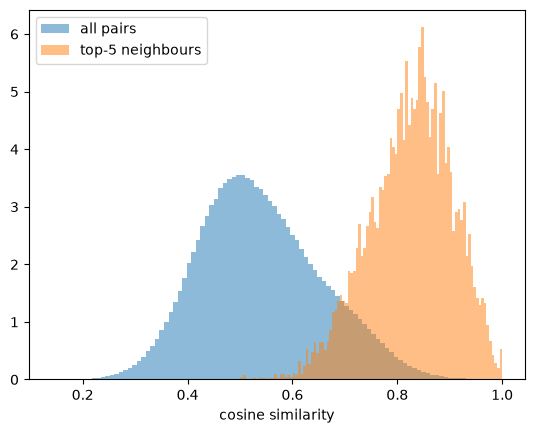

In [5]:
import matplotlib.pyplot as plt

idx = np.argsort(-S, axis=1)[:, :5]
top5 = np.take_along_axis(S, idx, axis=1)

print("percentiles of the score at each neighbour rank")
for r in range(5):
    print(r + 1, np.percentile(top5[:, r], [10, 25, 50, 75, 90]).round(3))

# background: all distinct pairs
bg = V @ V.T
bg = bg[np.triu_indices_from(bg, k=1)]
print("all pairs", np.percentile(bg, [50, 90, 99, 99.9]).round(3))

plt.hist(bg, bins=100, alpha=.5, density=True, label="all pairs")
plt.hist(top5.ravel(), bins=100, alpha=.5, density=True, label="top-5 neighbours")
plt.legend(); plt.xlabel("cosine similarity"); plt.show()

In [6]:
rng = np.random.default_rng(0)
ids = df["eventid"].to_numpy()

def pairs_at(c):
    out = set()
    for i in range(len(V)):
        for j, s in zip(idx[i], top5[i]):
            if s >= c:
                out.add((min(i, j), max(i, j)))
    return out

for c in [0.80, 0.85, 0.90]:
    p = pairs_at(c)
    touched = {k for pr in p for k in pr}
    print(c, "links:", len(p), "events covered:", len(touched), f"({len(touched)/len(V):.0%})")

# spot check: random pairs scoring just above each cut-off
for c in [0.80, 0.85]:
    band = [pr for pr in pairs_at(c) if S[pr] < c + 0.02]
    print(f"\n=== band {c} to {c+0.02}: {len(band)} pairs ===")
    for a, b in rng.choice(len(band), 4, replace=False).tolist() and [band[k] for k in rng.choice(len(band), 4, replace=False)]:
        print(f"{S[a, b]:.3f}\n  {ids[a]}: {df.summary_clean[a]}\n  {ids[b]}: {df.summary_clean[b]}\n")

0.8 links: 4216 events covered: 1260 (76%)
0.85 links: 2384 events covered: 919 (55%)
0.9 links: 940 events covered: 519 (31%)

=== band 0.8 to 0.8200000000000001: 718 pairs ===
0.806
  201508240051: Assailants opened fire on the vehicle of Nusrat Manghan in Gulshan-e-Iqbal neighborhood, Karachi city, Sindh province, Pakistan. Manghan, the Sindh Prisons Department Inspector General, was not in the vehicle at the time of the attack and there were no reported casualties. No group claimed responsibility for the incident.
  201508280038: Assailants opened fire on a civilian vehicle in North Nazimabad Town neighborhood, Karachi city, Sindh province, Pakistan. At least one person was killed in the assault. No group claimed responsibility for the attack.

0.812
  201009080015: On Wednesday morning, on Block 20 of the Federal B area of Karachi, Sindh, Pakistan, unknown assailants shot and killed two activists of Ahle Sunnat Wal Jamaat (ASWJ), Hafiz Inamullah and Hafiz Tahir. No group claimed r

In [7]:
d = df["dup_group"]
print(d.dtype, "null:", d.isna().sum())
print(d.value_counts().head(8))

sizes = d.value_counts()
print((sizes > 1).sum(), "values shared by 2+ events")

# show one shared group
k = sizes[sizes > 1].index[0]
for _, r in df[d == k].head(3).iterrows():
    print(r.eventid, r.date, r.summary_clean[:150], "\n")

int64 null: 0
dup_group
1120    2
268     2
288     2
1209    2
1035    2
124     2
711     2
638     2
Name: count, dtype: int64
9 values shared by 2+ events
201202250019 2012-02-25 00:00:00 Explosives planted along railway tracks detonated in Bin Qassim town, Sindh province, Pakistan. The tracks were damaged, but there were no human casua 

201202250020 2012-02-25 00:00:00 Explosives planted along railway tracks detonated in Bin Qassim town, Sindh province, Pakistan. The tracks were damaged, but there were no human casua 



In [8]:
dg = df["dup_group"].to_numpy()
p = pairs_at(0.85)
dups = [(a, b) for a, b in p if dg[a] == dg[b]]
print(len(p), "pairs at 0.85;", len(dups), "are dup_group pairs")
print("their scores:", sorted(S[a, b].round(3) for a, b in dups))

2384 pairs at 0.85; 9 are dup_group pairs
their scores: [np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0), np.float32(1.0)]


In [9]:
import sys, inspect
sys.path.append("../src")
import build_graph as bg

df = pd.read_parquet("../data/processed/karachi_events_clean.parquet")
actor_rows, source_rows, related_rows = bg.derived_rows(df)

print(actor_rows[0])
print(source_rows[0])
print(inspect.getsource(bg.load_links))

{'a': 200205010003, 'b': 200205010004, 'props': {'rule': 'same_actor_nearby', 'gap_days': 0, 'strength': 1.0, 'evidence': ['group: Muttahida Qami Movement (MQM)', 'gap_days: 0']}}
{'a': 200001280004, 'b': 200001280005, 'props': {'rule': 'same_source', 'strength': 3, 'evidence': ['Zahid Hussain, “Bomb kills four, wounds 28 in Karachi mosque,” The Associated Press, January 28, 2000.', '“Bomb explodes in congested old part of city wounding 4,” Associated Press Worldstream, January 28, 2000.', 'Zahid Hussain, “2 Bombs Explode in Pakistan, 4 Dead,” Associated Press Online, January 28, 2000.']}}
def load_links(driver, rel, rows):
    query = (
        "UNWIND $rows AS row "
        "MATCH (a:Event {eventid: row.a}) "
        "MATCH (b:Event {eventid: row.b}) "
        f"MERGE (a)-[r:{rel}]->(b) "
        "SET r += row.props"
    )
    for i in range(0, len(rows), BATCH):
        run(driver, query, rows=rows[i:i + BATCH])
    print(f"{rel}: {len(rows)} links sent")



In [10]:
from config import get_driver, run
driver = get_driver()

deg = run(driver, """
    MATCH (e:Event)-[:SIMILAR_TO]-() WITH e, count(*) AS d
    RETURN e.eventid AS id, d, e.summary_clean AS txt ORDER BY d DESC""")
d = pd.Series([r["d"] for r in deg])
print(d.describe())
print("events with degree > 10:", (d > 10).sum(), "| > 20:", (d > 20).sum())

for r in deg[:3]:
    print(r["id"], r["d"], r["txt"][:200], "\n")

count    919.000000
mean       5.181719
std        4.534382
min        1.000000
25%        2.000000
50%        5.000000
75%        6.000000
max       40.000000
dtype: float64
events with degree > 10: 86 | > 20: 12
201409160052 40 Assailants opened fire on police personnel in Karachi city, Sindh province, Pakistan. One police officer was killed in the attack. No group claimed responsibility for the incident. 

201407210032 32 Assailants opened fire on police officers in Quaidabad area, Karachi city, Sindh province, Pakistan. One police officer was killed and one wounded in the attack. No group claimed responsibility for th 

201408060028 30 An explosive device detonated near a police station in Quaidabad neighborhood, Karachi city, Sindh province, Pakistan. There were no reported casualties. No group claimed responsibility for the incide 



In [11]:
dg = df["dup_group"].to_numpy()
S2 = V @ V.T
np.fill_diagonal(S2, -1)
S2[dg[:, None] == dg[None, :]] = -1

nn = np.argsort(-S2, axis=1)[:, :5]
sel = [set(j for j in nn[i] if S2[i, j] >= 0.85) for i in range(len(V))]

current = {(min(i, j), max(i, j)) for i in range(len(V)) for j in sel[i]}
mutual = {(i, j) for i in range(len(V)) for j in sel[i] if i < j and i in sel[j]}

# cap: keep a pair only if neither side exceeds 10 links, strongest first
cap, deg, capped = 10, {}, set()
for a, b in sorted(current, key=lambda p: -S2[p]):
    if deg.get(a, 0) < cap and deg.get(b, 0) < cap:
        capped.add((a, b)); deg[a] = deg.get(a, 0) + 1; deg[b] = deg.get(b, 0) + 1

for name, p in [("current", current), ("mutual", mutual), ("cap 10", capped)]:
    d = pd.Series([k for pr in p for k in pr]).value_counts()
    print(f"{name:8} pairs {len(p):5} | events {len(d):4} ({len(d)/len(V):.0%}) | max degree {d.max():3} | >10: {(d > 10).sum()}")

current  pairs  2381 | events  919 (55%) | max degree  40 | >10: 86
mutual   pairs   928 | events  784 (47%) | max degree   5 | >10: 0
cap 10   pairs  1878 | events  906 (54%) | max degree  10 | >10: 0
